# Experiment 14: separate elemental readouts

Validation evaluation of **14-TensorNequIP-NMR-SeparateHeads-9136987**, directly compared with **13A** and **13B**.

All main comparisons use each run's **best validation checkpoint** and exactly the same 50 validation structures: **2,400 Si and 4,800 O sites**. The targets are absolute DFT isotropic shieldings, `MS_Iso_QM = trace(ms)/3`, in ppm. Every parity panel reports atom-pooled RMSE, MAE and R². The diagonal is perfect prediction, and axes are shared across runs within each element.

Experiment 14 starts from the E/F backbone with fresh, independent elemental heads (260 active trainable parameters). Experiments 13A/B continued NMR training from experiment 12; 13A used raw MSE and 13B used balanced standardised MSE. Experiment 14 retains 13B's relative loss weighting but removes the ×1000 multiplier. The comparison therefore measures observed validation performance; it is not an otherwise perfectly matched head-architecture ablation.

The predictions were generated by fresh full-model inference. Reruns reuse checksum-verified predictions unless `RECOMPUTE = True` is selected. The notebook verifies checkpoint provenance and reproduces the earlier 13A/B metrics. It does not train models or read training/test structures.


## Results and interpretation

Experiment 14 improves RMSE, MAE and R² for both elements relative to both shared-head baselines.

- **Si:** RMSE **2.812 ppm**, MAE **1.963 ppm**, R² **0.904**. RMSE changes by -1.390 ppm versus 13A and -0.412 ppm versus 13B (negative means improvement).
- **O:** RMSE **6.465 ppm**, MAE **4.086 ppm**, R² **0.905**. RMSE changes by -0.256 ppm versus 13A and -1.377 ppm versus 13B (negative means improvement).

The silicon parity plot tightens substantially relative to 13A. Oxygen recovers the accuracy sacrificed in 13B and improves modestly on 13A. Both elements still show compression toward the mean, with remaining large oxygen errors at the low-shielding end.

Experiment 14 selected epoch **1,972**; its last checkpoint is epoch **1,979**, with **7** checks since the best score. The saved run reached neither the 5,000-epoch ceiling nor 300 checks without improvement. These files do not establish convergence or the precise scheduler exit reason; the Slurm output/accounting record would be needed to confirm a wall-time termination.

All compared backbones match the original E/F checkpoint exactly. Differences in predictions therefore arise downstream of those frozen features. An improvement in 14 supports the usefulness of separate elemental readout weights for this dataset, but the runs also differ in NMR initialisation and training history. The 13A comparison additionally changes elemental loss weighting. These runs alone do not isolate every causal contribution.

Compare elemental errors in ppm and R², not the height of the total-loss curves: 13A uses raw MSE ×1000, 13B uses standardised MSE ×1000, and 14 uses standardised MSE without that multiplier.

This is a validation-set assessment on data already used for checkpoint selection, not an independent test-set result. Bootstrap intervals resample whole structures and describe uncertainty from this validation sample; they do not measure variability between training seeds.

## Setup and input provenance

In [1]:
from pathlib import Path
import copy, hashlib, json, os, sys
os.environ.setdefault('MPLCONFIGDIR', '/tmp/nequip14-eval-mpl')
os.environ.setdefault('XDG_CACHE_HOME', '/tmp/nequip14-cache')
import numpy as np
import pandas as pd
import torch
import yaml
from ase.io import read
from graph_pes.atomic_graph import AtomicGraph
from IPython.display import display, Image
import matplotlib.pyplot as plt

NAME = '14-TensorNequIP-NMR-SeparateHeads-9136987'
ROOT = Path('/Users/louismcauliffe/code/research/NequIP_experiments')
sys.path.insert(0, str(ROOT))
import nmr_helpers
import nmr_helpers.element_heads
torch.set_num_threads(4)
torch.set_default_dtype(torch.float32)
# The build process sets ARTIFACT_DIR; normal notebook reruns use experiments/.
OUT = Path(globals().get('ARTIFACT_DIR', ROOT/'experiments'/(NAME+'-figures')))
OUT.mkdir(parents=True, exist_ok=True)

RUNS = {
    '13A': '13A-TensorNequIP-NMR-Continue-9121328',
    '13B': '13B-TensorNequIP-NMR-Balanced-9121329',
    '14': NAME,
}
def sha(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()
def same(a, b):
    if torch.is_tensor(a):
        return torch.is_tensor(b) and torch.equal(a, b)
    if isinstance(a, dict):
        return a.keys() == b.keys() and all(same(a[k], b[k]) for k in a)
    if isinstance(a, (tuple, list)):
        return type(a) == type(b) and len(a) == len(b) and all(same(x,y) for x,y in zip(a,b))
    return a == b
hashes, models, configs, provenance = {}, {}, {}, []
def record_hash(path):
    hashes[str(path)] = sha(path)

# Load trusted local exports for architecture, then strictly load best.ckpt.
# Experiment 14's last checkpoint is an additional diagnostic, not a baseline.
for run, folder in RUNS.items():
    directory = ROOT/'graph-pes-results'/folder
    config = yaml.safe_load((directory/'train-config.yaml').read_text())
    configs[run] = config
    assert config['data']['valid']['path'] == 'data/nmr_iso/valid.xyz'
    assert config['data']['test'] is None
    for filename in ['model.pt', 'checkpoints/best.ckpt', 'checkpoints/last.ckpt', 'train-config.yaml']:
        record_hash(directory/filename)
    exported = torch.load(directory/'model.pt', map_location='cpu', weights_only=False)
    best = torch.load(directory/'checkpoints/best.ckpt', map_location='cpu', weights_only=False)
    last = torch.load(directory/'checkpoints/last.ckpt', map_location='cpu', weights_only=False)
    def weights(checkpoint):
        return {k.removeprefix('model.'):v for k,v in checkpoint['state_dict'].items() if k.startswith('model.')}
    export_matches = same(exported.state_dict(), weights(best))
    for which, checkpoint in [('best', best)] + ([('last', last)] if run == '14' else []):
        model = copy.deepcopy(exported)
        model.load_state_dict(weights(checkpoint), strict=True)
        models[run, which] = model.eval().requires_grad_(False)
    callbacks = last.get('callbacks', {})
    selection = next(v for k,v in callbacks.items()
                     if k.startswith('ModelCheckpoint') and v.get('monitor') == 'valid/loss/total')
    early = next((v for k,v in callbacks.items() if k.startswith('EarlyStopping')), {})
    provenance.append(dict(run=run, directory=folder, best_epoch=int(best['epoch'])+1,
        last_epoch=int(last['epoch'])+1, best_step=int(best['global_step']),
        last_step=int(last['global_step']), max_epochs=config['fitting']['trainer_kwargs']['max_epochs'],
        checks_since_best=(early['total_checks']-early['best_val_loss_check']
                           if 'total_checks' in early else early.get('wait_count',0)),
        stopped_epoch=early.get('stopped_epoch',0),
        final_lr=last['optimizer_states'][0]['param_groups'][0]['lr'],
        export_matches_best=export_matches, selected_loss=float(selection['best_model_score'])))
provenance = pd.DataFrame(provenance)
display(provenance[['run','best_epoch','last_epoch','max_epochs','checks_since_best','final_lr','export_matches_best']])

source_path = ROOT/'graph-pes-results/Kavanagh-Med-9059603/model.pt'
record_hash(source_path)
ef_model = torch.load(source_path, map_location='cpu', weights_only=False)
backbone_equal = {}
for (run, which), model in models.items():
    backbone_equal[f'{run}/{which}'] = all(same(
        getattr(model.models['nequip'], part).state_dict(),
        getattr(ef_model.models['nequip'], part).state_dict())
        for part in ('Z_embedding','initial_node_embedding','edge_embedding','layers'))
assert all(backbone_equal.values()), backbone_equal
assert models['14','best'].models['nequip'].tensor_readout.weight.numel() == 256
del ef_model

,run,best_epoch,last_epoch,max_epochs,checks_since_best,final_lr,export_matches_best
0,13A,1948,2248,3000,300,0.000011,True
1,13B,2567,2867,3000,300,0.000004,True
2,14,1972,1979,5000,7,0.000084,True


## Validation predictions

In [2]:
validation_path = ROOT/'data/nmr_iso/valid.xyz'
record_hash(validation_path)
frames = read(validation_path, index=':')
assert len(frames) == 50
# Set True to rerun all 200 full-model forwards. Saved predictions are reused
# only when their checksum and every recorded input checksum match.
RECOMPUTE = False
cache_valid = False
if not RECOMPUTE and (OUT/'manifest.json').exists() and (OUT/'predictions.csv.gz').exists():
    saved_manifest = json.loads((OUT/'manifest.json').read_text())
    cache_valid = (saved_manifest.get('evaluated_split') == 'validation'
        and saved_manifest.get('fresh_full_model_inference') is True
        and sha(OUT/'predictions.csv.gz') == saved_manifest['prediction_sha256']
        and all(saved_manifest['files_sha256'].get(p) == digest for p,digest in hashes.items())
        and all(Path(p).is_file() and sha(p) == digest for p,digest in saved_manifest['files_sha256'].items()))
if cache_valid:
    sites = pd.read_csv(OUT/'predictions.csv.gz', dtype={'run':str})
    print('Reusing verified predictions from the completed full-model validation inference.')
else:
    records = []
    with torch.inference_mode():
        for structure, atoms in enumerate(frames):
            # Labels stay outside the graph: inference receives geometry/elements only.
            graph = AtomicGraph.from_ase(atoms, cutoff=6.0)
            assert not graph.properties
            reference = np.asarray(atoms.arrays['MS_Iso_QM'], dtype=np.float64)
            assert reference.shape == (len(atoms),)
            for (run, checkpoint), model in models.items():
                prediction = model.predict(graph, ['tensor'])['tensor'].detach().cpu().numpy()
                assert prediction.shape == reference.shape and np.isfinite(prediction).all()
                records.append(pd.DataFrame(dict(run=run, checkpoint=checkpoint,
                    structure=structure, atom=np.arange(len(atoms)),
                    element=atoms.get_chemical_symbols(), reference=reference, prediction=prediction)))
            if (structure+1) % 10 == 0:
                print(f'Evaluated {structure+1}/50 structures for all four model/checkpoint combinations.', flush=True)
    sites = pd.concat(records, ignore_index=True)
sites['error'] = sites.prediction-sites.reference
assert sites.groupby(['run','checkpoint','element']).size().tolist() == [4800,2400]*4
print('Validation only: 50 structures, 2,400 Si sites and 4,800 O sites per checkpoint.')

Reusing verified predictions from the completed full-model validation inference.
Validation only: 50 structures, 2,400 Si sites and 4,800 O sites per checkpoint.


## Metrics and checkpoint consistency

In [3]:
rows = []
for (run, checkpoint, element), group in sites.groupby(['run','checkpoint','element'], sort=False):
    y, p = group.reference.to_numpy(), group.prediction.to_numpy()
    error = p-y
    rows.append(dict(run=run, checkpoint=checkpoint, element=element, N=len(y),
        RMSE=float(np.sqrt(np.mean(error**2))), MAE=float(np.mean(abs(error))),
        R2=float(1-np.sum(error**2)/np.sum((y-y.mean())**2)),
        bias=float(error.mean()), prediction_std=float(p.std()), target_std=float(y.std()),
        slope=float(np.polyfit(y,p,1)[0])))
metrics = pd.DataFrame(rows)
best_metrics = metrics.query('checkpoint == "best"').copy()
display(best_metrics[['run','element','N','RMSE','MAE','R2']].round(4))

objective_checks = []
for run in RUNS:
    m = best_metrics.query('run == @run').set_index('element')
    si, oxygen = m.loc['Si','RMSE']**2, m.loc['O','RMSE']**2
    if run == '13A':
        objective = 1000*(si+2*oxygen)/3
    else:
        loss_config = configs[run]['loss']['isotropy']['+nmr_helpers.shared_head_training.ElementBalancedMSE']
        objective = loss_config['weight']*.5*(si/loss_config['si_std']**2+oxygen/loss_config['o_std']**2)
    selected = float(provenance.set_index('run').loc[run,'selected_loss'])
    assert np.isclose(objective, selected, rtol=5e-4), (run, objective, selected)
    objective_checks.append(dict(run=run, recomputed=objective, saved=selected))

# Independently reproduce the earlier 13A/13B validation metrics.
previous_path = ROOT/'experiments/13-TensorNequIP-MSIsotropy-Shared-Head-Evaluation-figures/metrics.csv'
record_hash(previous_path)
previous = pd.read_csv(previous_path, dtype={'run':str})
previous = previous.query('split == "valid" and checkpoint == "best"').set_index(['run','element'])
for row in best_metrics.query('run != "14"').itertuples():
    for metric in ['RMSE','MAE','R2']:
        assert np.isclose(getattr(row,metric), previous.loc[(row.run,row.element),metric], atol=2e-5, rtol=1e-5)
print('Saved validation objectives and previous 13A/13B results reproduced.')

Saved validation objectives and previous 13A/13B results reproduced.


,run,element,N,RMSE,MAE,R2
0,13A,O,4800,6.7212,4.2887,0.8971
1,13A,Si,2400,4.2013,3.0271,0.7851
2,13B,O,4800,7.8415,4.9548,0.8599
3,13B,Si,2400,3.2241,2.2715,0.8734
4,14,O,4800,6.4648,4.0862,0.9048
5,14,Si,2400,2.8117,1.9635,0.9038


## Parity plots, with common axes for each element

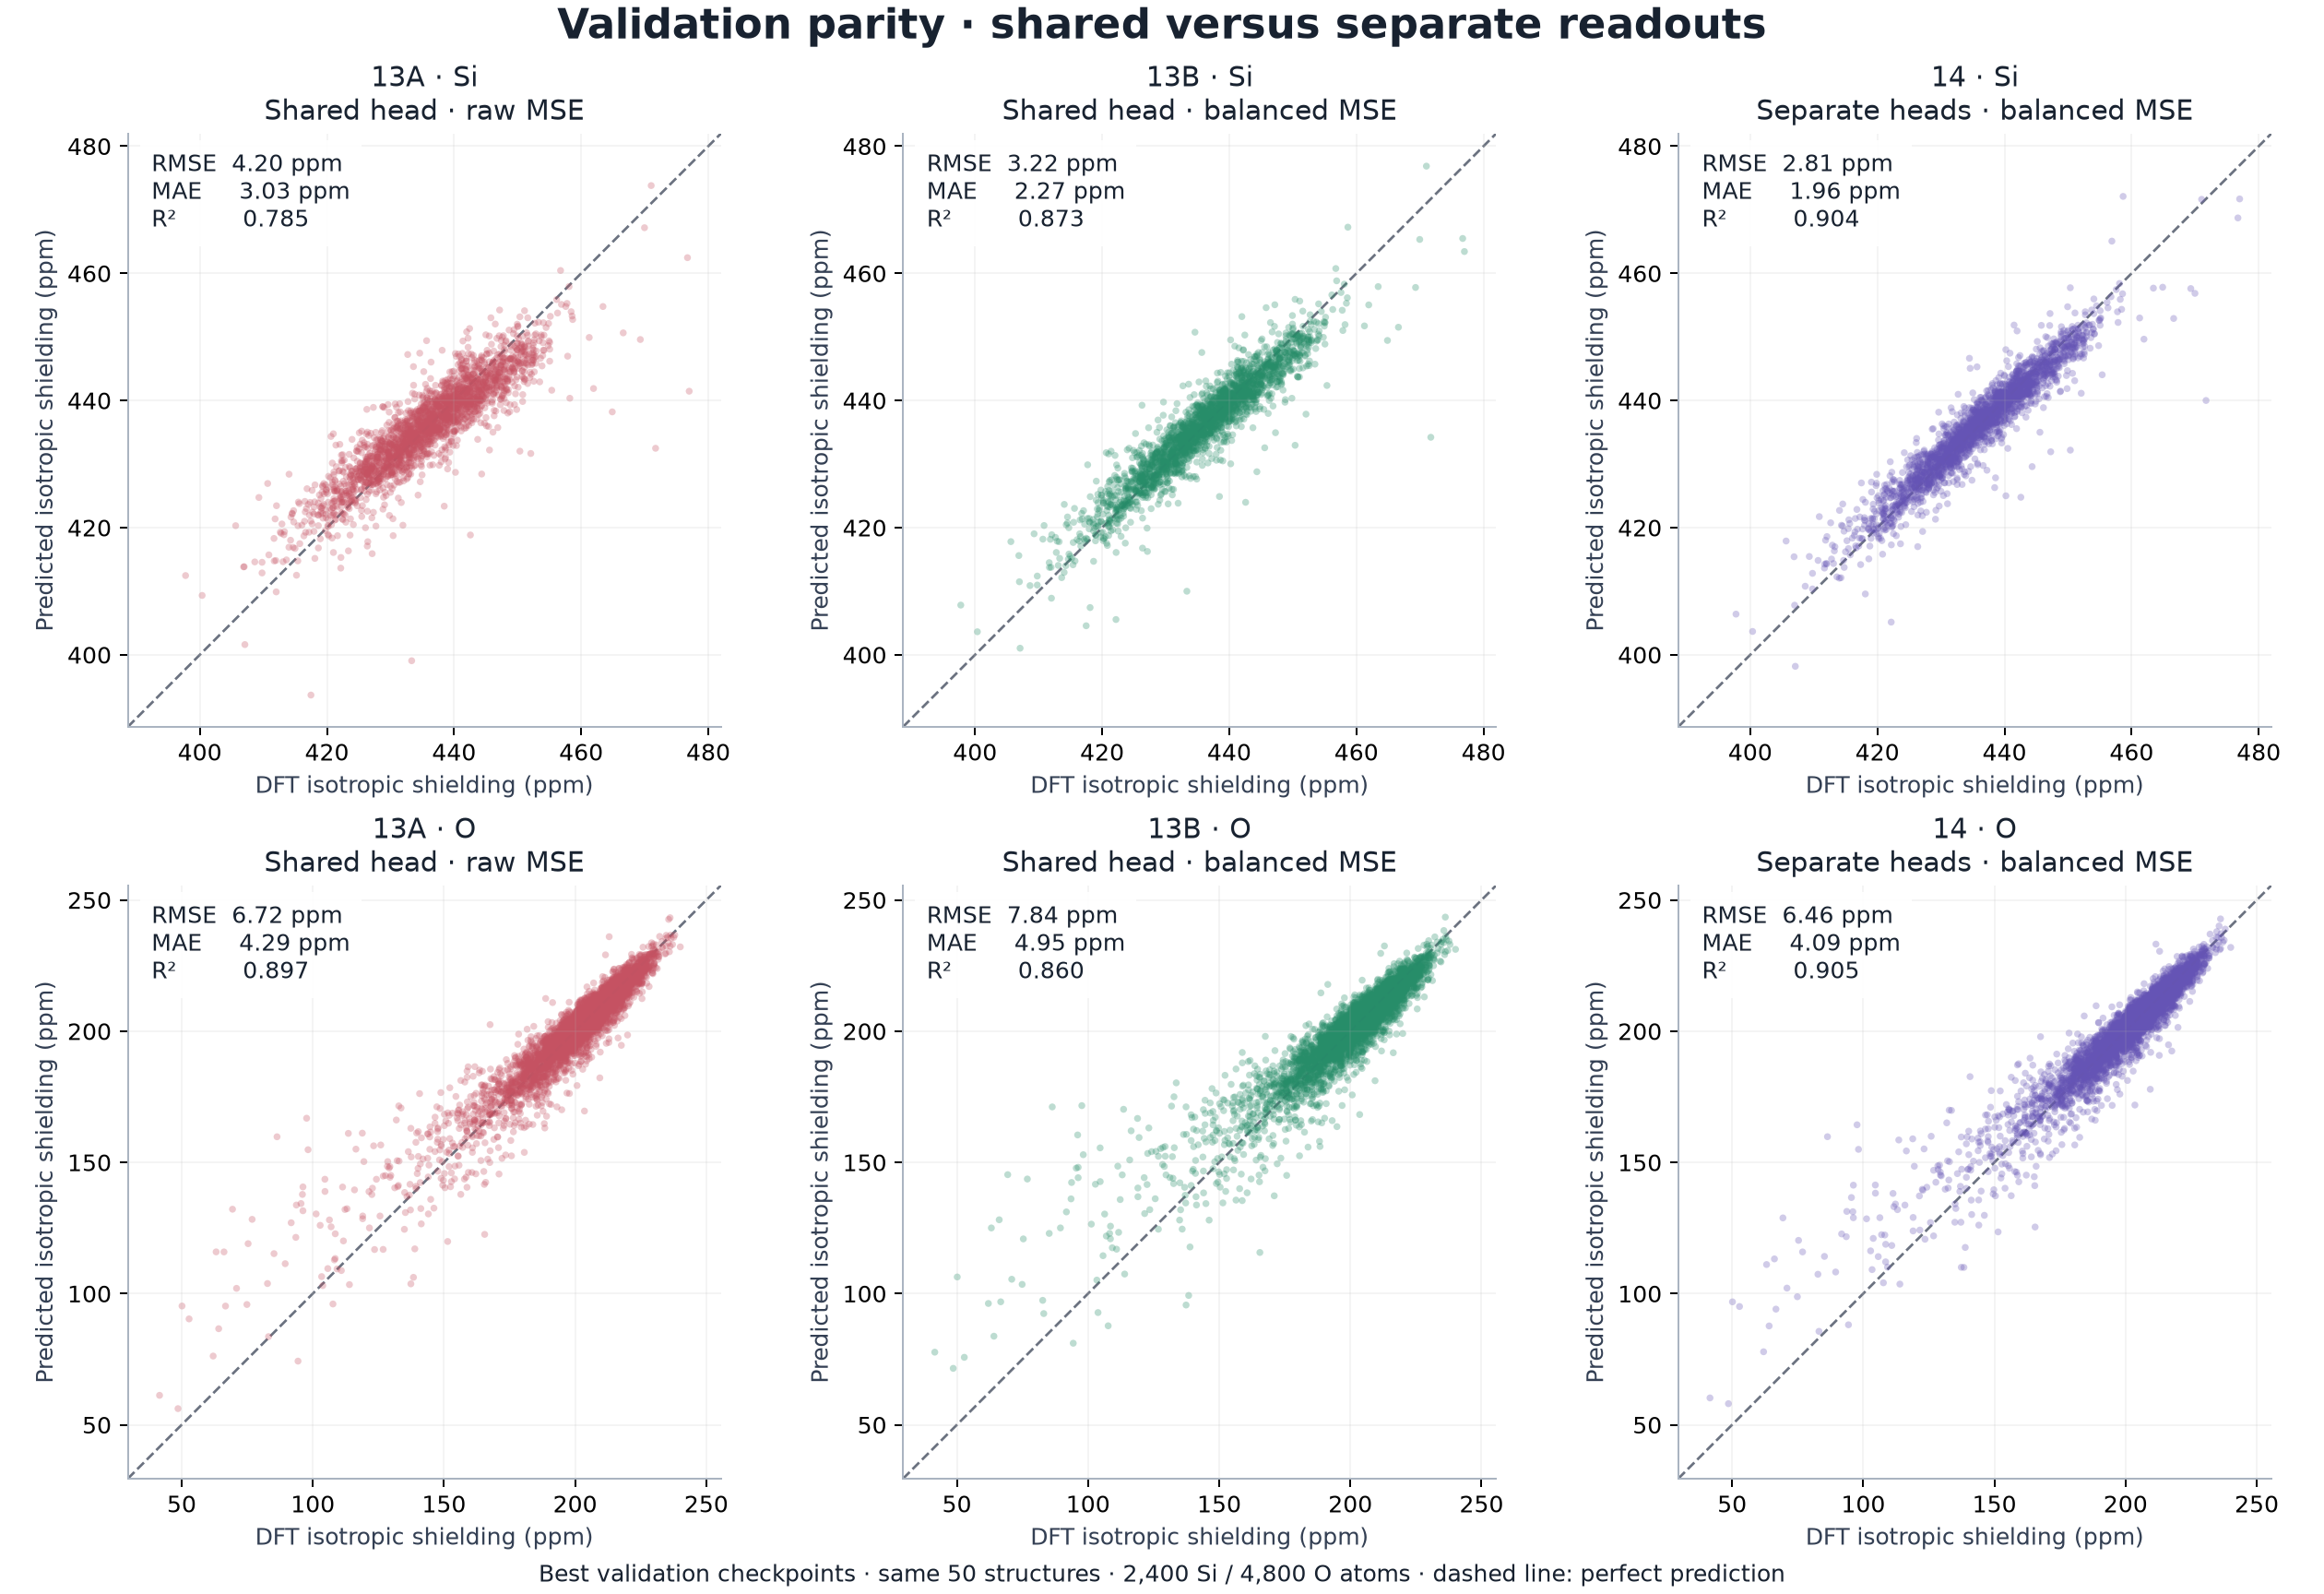

In [4]:
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,
    'axes.spines.top':False,'axes.spines.right':False,'axes.edgecolor':'#AAB4C1',
    'text.color':'#182230','axes.labelcolor':'#344054','savefig.facecolor':'white'})
colors = {'13A':'#C55262','13B':'#278D69','14':'#6554B5'}
descriptions = {'13A':'Shared head · raw MSE','13B':'Shared head · balanced MSE','14':'Separate heads · balanced MSE'}
best_sites = sites.query('checkpoint == "best"')
def draw_parity(ax, run, element):
    all_element = best_sites.query('element == @element')
    lo = min(all_element.reference.min(), all_element.prediction.min())
    hi = max(all_element.reference.max(), all_element.prediction.max())
    pad = .06*(hi-lo)
    limits = (lo-pad, hi+pad)
    group = all_element.query('run == @run')
    m = best_metrics.query('run == @run and element == @element').iloc[0]
    ax.scatter(group.reference, group.prediction, s=9, alpha=.3, color=colors[run],
               edgecolors='none', rasterized=True)
    ax.plot(limits, limits, '--', lw=1.1, color='#6B7280', zorder=0)
    ax.set(xlim=limits, ylim=limits, aspect='equal', xlabel='DFT isotropic shielding (ppm)',
           ylabel='Predicted isotropic shielding (ppm)', title=f'{run} · {element}\n{descriptions[run]}')
    ax.text(.04,.97, f'RMSE  {m.RMSE:.2f} ppm\nMAE     {m.MAE:.2f} ppm\nR²         {m.R2:.3f}',
            transform=ax.transAxes, va='top', fontsize=10,
            bbox=dict(facecolor='white', alpha=.94, edgecolor='none', pad=5))
    ax.grid(alpha=.13)

fig, axes = plt.subplots(2,3,figsize=(14,9.6),layout='constrained')
for row, element in enumerate(['Si','O']):
    for col, run in enumerate(RUNS):
        draw_parity(axes[row,col], run, element)
fig.suptitle('Validation parity · shared versus separate readouts', fontsize=18, weight='bold')
fig.supxlabel('Best validation checkpoints · same 50 structures · 2,400 Si / 4,800 O atoms · dashed line: perfect prediction', fontsize=10)
for extension in ['png','pdf']:
    fig.savefig(OUT/f'validation-parity.{extension}', dpi=180)
plt.close(fig)
display(Image(filename=str(OUT/'validation-parity.png')))
for element in ['Si','O']:
    fig, axes = plt.subplots(1,3,figsize=(14,4.8),layout='constrained')
    for ax, run in zip(axes, RUNS):
        draw_parity(ax, run, element)
    fig.suptitle(f'{element} · validation parity', fontsize=17, weight='bold')
    for extension in ['png','pdf']:
        fig.savefig(OUT/f'parity-{element}.{extension}', dpi=180)
    plt.close(fig)

## Direct comparison with 13A and 13B

In [5]:
comparisons = []
indexed = best_metrics.set_index(['run','element'])
for baseline in ['13A','13B']:
    for element in ['Si','O']:
        old, new = indexed.loc[(baseline,element)], indexed.loc[('14',element)]
        comparisons.append(dict(baseline=baseline, comparison='14', element=element,
            RMSE_baseline=old.RMSE, RMSE_14=new.RMSE, RMSE_delta=new.RMSE-old.RMSE,
            RMSE_reduction_percent=100*(1-new.RMSE/old.RMSE),
            MAE_baseline=old.MAE, MAE_14=new.MAE, MAE_delta=new.MAE-old.MAE,
            MAE_reduction_percent=100*(1-new.MAE/old.MAE), R2_delta=new.R2-old.R2))
comparisons = pd.DataFrame(comparisons)
display(comparisons.round(4))
print('Positive reduction percentages mean lower error in experiment 14.')

# Paired bootstrap over structures, retaining correlated atoms together.
structure_errors = best_sites.assign(squared_error=lambda d:d.error**2).groupby(
    ['run','element','structure']).agg(SSE=('squared_error','sum'),N=('squared_error','size')).reset_index()
draws = np.random.default_rng(42).integers(0,50,size=(4000,50))
bootstrap = {}
for (run, element), group in structure_errors.groupby(['run','element']):
    group = group.sort_values('structure')
    bootstrap[run,element] = np.sqrt(group.SSE.to_numpy()[draws].sum(1)/group.N.to_numpy()[draws].sum(1))
intervals = []
for baseline in ['13A','13B']:
    for element in ['Si','O']:
        difference = bootstrap['14',element]-bootstrap[baseline,element]
        low, high = np.quantile(difference,[.025,.975])
        intervals.append(dict(baseline=baseline, comparison='14', element=element,
                              delta_RMSE_95_low=low, delta_RMSE_95_high=high))
intervals = pd.DataFrame(intervals)
display(intervals.round(4))
print('Intervals below zero favour experiment 14; these quantify validation-structure sampling, not training-seed uncertainty.')

Positive reduction percentages mean lower error in experiment 14.
Intervals below zero favour experiment 14; these quantify validation-structure sampling, not training-seed uncertainty.


,baseline,comparison,element,RMSE_baseline,RMSE_14,RMSE_delta,RMSE_reduction_percent,MAE_baseline,MAE_14,MAE_delta,MAE_reduction_percent,R2_delta
0,13A,14,Si,4.2013,2.8117,-1.3897,33.0772,3.0271,1.9635,-1.0636,35.1371,0.1187
1,13A,14,O,6.7212,6.4648,-0.2564,3.8141,4.2887,4.0862,-0.2025,4.7225,0.0077
2,13B,14,Si,3.2241,2.8117,-0.4125,12.7935,2.2715,1.9635,-0.3080,13.5603,0.0303
3,13B,14,O,7.8415,6.4648,-1.3767,17.5565,4.9548,4.0862,-0.8686,17.5307,0.0449


,baseline,comparison,element,delta_RMSE_95_low,delta_RMSE_95_high
0,13A,14,Si,-1.5976,-1.2022
1,13A,14,O,-0.3215,-0.1855
2,13B,14,Si,-0.5201,-0.3184
3,13B,14,O,-1.7167,-1.0457


## Best versus last checkpoint and saved outputs

In [6]:
display(metrics.query('run == "14"')[['checkpoint','element','RMSE','MAE','R2']].round(5))
scales = []
for (run, checkpoint), model in models.items():
    for z, element in [(14,'Si'),(8,'O')]:
        scales.append(dict(run=run, checkpoint=checkpoint, element=element,
            scale=float(model.models['nequip'].scaler.per_element_scaling[z]),
            offset=float(model.models['offset']._offsets[z])))
scales = pd.DataFrame(scales)
for name, frame in [('metrics',metrics),('provenance',provenance),('comparisons',comparisons),
                    ('paired-rmse-changes',intervals),('scales',scales)]:
    frame.to_csv(OUT/f'{name}.csv', index=False)
sites.to_csv(OUT/'predictions.csv.gz', index=False)
for path, digest in hashes.items():
    assert sha(path) == digest, f'Input changed during evaluation: {path}'
manifest = dict(files_sha256=hashes, evaluated_split='validation', structures=50,
    sites_per_model={'Si':2400,'O':4800}, fresh_full_model_inference=True,
    backbone_matches_EF_source=backbone_equal, no_training_performed=True,
    test_or_training_data_accessed=False, objective_checks=objective_checks,
    previous_13_metrics_reproduced=True, cpu_vs_gpu_objective_rtol=5e-4,
    prediction_sha256=sha(OUT/'predictions.csv.gz'), torch_version=torch.__version__,
    metrics_definition='Atom-pooled RMSE and MAE; R2 = 1 - SSE/SST within each element; absolute DFT isotropic shieldings in ppm.')
(OUT/'manifest.json').write_text(json.dumps(manifest,indent=2))
print('Saved parity plots, predictions, metrics, comparisons and provenance to:', OUT)

Saved parity plots, predictions, metrics, comparisons and provenance to: /Users/louismcauliffe/.codex/.chatgpt-projects/g-p-6aa93f0341cc8191bbd47fb85a4101fb/outputs/experiment-14-evaluation/staged/14-TensorNequIP-NMR-SeparateHeads-9136987-figures


,checkpoint,element,RMSE,MAE,R2
4,best,O,6.46482,4.08616,0.90476
5,best,Si,2.81166,1.96348,0.90375
6,last,O,6.46563,4.08460,0.90473
7,last,Si,2.81419,1.95955,0.90358
